## Multimodal RAG, GraphRAG and vectorless RAG (PageIndex)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/en/7_5_Multimodal_graph_vectorless_RAG_en.ipynb)

| | |
|---|---|
| 🎯 **What you'll learn** | Three RAG patterns beyond "chunk + embed + top-k": Docling + multimodal RAG over tables and charts, GraphRAG over a company ownership graph (networkx agent and Neo4j + Cypher), and vectorless, tree-navigating RAG in the style of PageIndex. |
| 🔑 **API keys** | `OPENAI_API_KEY`; optional `NEO4J_URI`, `NEO4J_USERNAME`, `NEO4J_PASSWORD` |
| 💲 **API cost** | low – about 20 short requests, two of them with an image |
| ⏱️ **Run time** | 2–4 min (the first Docling run downloads its layout models) |

Classic RAG splits text into chunks, embeds them and returns the most *similar* ones. It works well for questions whose answer sits in one paragraph of plain text. It struggles when:

| Problem | Example | Pattern from this notebook |
|---|---|---|
| the answer is in a **table, chart or scan** | "In which quarter was the EBITDA margin lowest?" (value only on a chart) | **Docling + multimodal RAG**, ColPali |
| the answer needs **relations across many documents** | "Which companies are indirectly linked to person X through common shareholders?" | **GraphRAG**, Neo4j + Cypher |
| the document is **long and well structured** and similarity search returns fragments without context | financial and legal reports, prospectuses | **vectorless RAG** (PageIndex) |

All three parts use one synthetic dataset: the annual report of the fictional company *Nordwind Logistics S.A.* and its ownership network.

### Install libraries

In [20]:
# Install this notebook's direct dependencies.
# Skipped when pip is missing, e.g. in the `uv sync` environment, which already has them (see README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langchain langchain-openai langchain-text-splitters langchain-neo4j docling networkx reportlab matplotlib pandas python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.

Note: you may need to restart the kernel to use updated packages.


### Models

In [21]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

load_dotenv()

llm = ChatOpenAI(model="gpt-6.1-terra", reasoning_effort="none", temperature=0)  # multimodal: text + images
embeddings = OpenAIEmbeddings()

### Sample data: an annual report as a PDF

We generate the PDF ourselves, so the notebook has no external files. It deliberately mixes three kinds of content:
- **text** with a numbered heading hierarchy (used later by PageIndex),
- a **table** of revenue by segment,
- a **chart** whose quarterly values appear *nowhere* in the text – only a model that can read images can answer questions about them.

In [22]:
REPORT = {
    "title": "Nordwind Logistics S.A. – Annual Report 2025",
    "sections": [
        ("1. Company overview",
         "Nordwind Logistics S.A. is a Gdańsk-based logistics group founded in 2009. It operates road freight, "
         "sea freight forwarding and contract warehousing in Poland, Germany and the Baltic states. "
         "At the end of 2025 the group employed 2,340 people and operated a fleet of 610 trucks."),
        ("2. Financial results",
         "In 2025 revenue grew by 4.4% to PLN 802 million, while net profit decreased to PLN 31 million "
         "(2024: PLN 38 million) because of higher personnel and fuel costs."),
        ("2.1. Revenue",
         "Growth was driven by road freight and warehousing; sea freight declined after the end of a large "
         "contract with a Scandinavian retailer. Revenue by segment (PLN million) is shown in Table 1."),
        ("2.2. Costs",
         "Operating costs rose to PLN 741 million. Personnel costs were 31% and fuel 28% of operating costs. "
         "Quarterly EBITDA margin is presented in Figure 1."),
        ("3. Ownership structure",
         "Shareholders: Anna Kowalska 34%, Amber Holdings Ltd 26%, Piotr Nowak 15%, free float 25%. "
         "Anna Kowalska is also the Chair of the Supervisory Board."),
        ("4. Risk factors",
         "The board identifies market and operational risks described below."),
        ("4.1. Market risks",
         "About 41% of revenue is invoiced in EUR, so the group is exposed to EUR/PLN exchange rate changes. "
         "The group hedges 60% of the expected net EUR position with 12-month FX forwards. "
         "Diesel price changes are passed on to clients through fuel surcharge clauses with a one-month delay."),
        ("4.2. Operational risks",
         "The main operational risk is the shortage of professional drivers; driver turnover was 18% in 2025. "
         "EU Mobility Package rules increase the cost of international road transport."),
    ],
    "table_title": "Table 1. Revenue by segment (PLN million)",
    "table": [["Segment", "2024", "2025"],
              ["Road freight", "388", "412"],
              ["Sea freight", "251", "236"],
              ["Warehousing", "129", "154"],
              ["Total", "768", "802"]],
    "figure_title": "Figure 1. EBITDA margin by quarter, 2025",
    "figure_quarters": {"Q1": 9.8, "Q2": 11.2, "Q3": 12.6, "Q4": 8.1},
}

In [23]:
import tempfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import Image, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

WORK_DIR = Path(tempfile.mkdtemp())
PDF_PATH = WORK_DIR / "nordwind_annual_report_2025.pdf"

# DejaVu Sans ships with matplotlib and, unlike the built-in PDF fonts, has Polish characters
pdfmetrics.registerFont(TTFont("DejaVu", Path(matplotlib.get_data_path()) / "fonts/ttf/DejaVuSans.ttf"))

# the chart: the quarterly values exist only in this image
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(list(REPORT["figure_quarters"]), list(REPORT["figure_quarters"].values()), color="#2b6cb0")
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylabel("EBITDA %")
ax.set_ylim(0, 15)
ax.set_title(REPORT["figure_title"])
fig.tight_layout()
chart_path = WORK_DIR / "ebitda.png"
fig.savefig(chart_path, dpi=150)
plt.close(fig)

styles = getSampleStyleSheet()
for style in styles.byName.values():
    style.fontName = "DejaVu"

story = [Paragraph(REPORT["title"], styles["Title"])]
for heading, text in REPORT["sections"]:
    level = "Heading2" if heading.count(".") > 1 else "Heading1"  # "2.1." is a subsection
    story += [Paragraph(heading, styles[level]), Paragraph(text, styles["BodyText"])]
    if heading.startswith("2.1."):
        story += [Spacer(1, 6), Paragraph(REPORT["table_title"], styles["Italic"]),
                  Table(REPORT["table"], colWidths=[240, 110, 110], hAlign="LEFT", style=TableStyle([
                      ("FONTNAME", (0, 0), (-1, -1), "DejaVu"),
                      ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
                      ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey)]))]
    if heading.startswith("2.2."):
        story += [Spacer(1, 6), Image(str(chart_path), width=420, height=210)]

SimpleDocTemplate(str(PDF_PATH)).build(story)
print("PDF:", PDF_PATH)

PDF: /tmp/tmp260tj7s9/nordwind_annual_report_2025.pdf


## Part 1. Docling: from PDF to a structured document

[Docling](https://github.com/docling-project/docling) (IBM, open source) converts PDF, DOCX, PPTX, HTML and images into a `DoclingDocument`. Unlike `PyPDFLoader`, which returns a flat string per page, Docling runs layout analysis and keeps the **structure**: headings and their levels, paragraphs, tables as rows and cells, and figures as images with captions. Everything runs locally.

In [24]:
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption

pipeline_options = PdfPipelineOptions(
    do_ocr=False,                  # our PDF has a text layer; turn OCR on for scans
    do_table_structure=True,       # rebuild tables as rows and cells
    generate_picture_images=True,  # keep figures as images for the multimodal part
    images_scale=2.0,
)
converter = DocumentConverter(
    format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=pipeline_options)}
)
doc = converter.convert(PDF_PATH).document

report_md = doc.export_to_markdown()
print(report_md)

Loading weights: 100%|██████████| 770/770 [00:00<00:00, 12569.82it/s]


## Nordwind Logistics S.A. - Annual Report 2025

## 1. Company overview

Nordwind Logistics S.A. is a Gdańsk-based logistics group founded in 2009. It operates road freight, sea freight forwarding and contract warehousing in Poland, Germany and the Baltic states. At the end of 2025 the group employed 2,340 people and operated a fleet of 610 trucks.

## 2. Financial results

In 2025 revenue grew by 4.4% to PLN 802 million, while net profit decreased to PLN 31 million (2024: PLN 38 million) because of higher personnel and fuel costs.

## 2.1. Revenue

Growth was driven by road freight and warehousing; sea freight declined after the end of a large contract with a Scandinavian retailer. Revenue by segment (PLN million) is shown in Table 1.

Table 1. Revenue by segment (PLN million)

| Segment      |   2024 |   2025 |
|--------------|--------|--------|
| Road freight |    388 |    412 |
| Sea freight  |    251 |    236 |
| Warehousing  |    129 |    154 |
| Total        |    768 |    802 |


Tables come back as data, not as text, so they can go straight to pandas:

,0,1,2
0,Segment,2024,2025
1,Road freight,388,412
2,Sea freight,251,236
3,Warehousing,129,154
4,Total,768,802


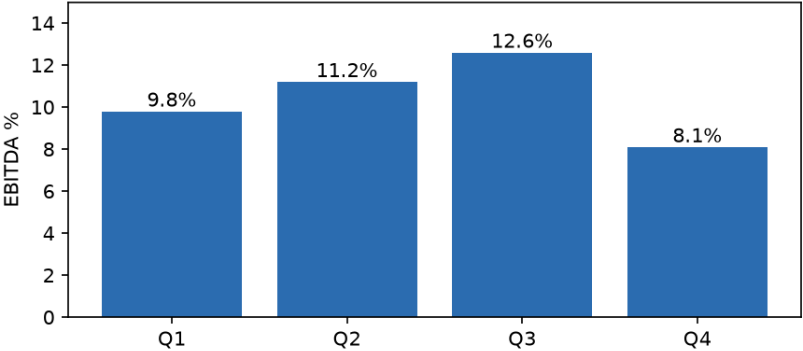

In [25]:
for table in doc.tables:
    display(table.export_to_dataframe(doc=doc))

for picture in doc.pictures:
    display(picture.get_image(doc))

### Multimodal RAG: searching text, tables and images

We use the **multi-vector** pattern:
1. every element gets a **text representation used for search** – a text chunk is itself, a table gets an LLM summary, a figure gets a description written by a vision model,
2. the vector store keeps that representation and, in metadata, the **original element** (table in Markdown, image in base64),
3. after retrieval the model receives the original – including the image itself – not the summary.

This way the answer is grounded in the source, and a summary that missed a detail does not limit it.

In [26]:
import base64
import io

from langchain_core.documents import Document
from langchain_core.messages import HumanMessage
from langchain_text_splitters import MarkdownHeaderTextSplitter


def image_to_b64(pil_image) -> str:
    buffer = io.BytesIO()
    pil_image.save(buffer, format="PNG")
    return base64.b64encode(buffer.getvalue()).decode()


def describe_image(b64: str) -> str:
    message = HumanMessage(content=[
        {"type": "text", "text": "Describe this figure from a financial report for search indexing. "
                                 "Include the title, axes, every data label and its value, and the main trend."},
        {"type": "image", "base64": b64, "mime_type": "image/png"},
    ])
    return llm.invoke([message]).content


def summarize_table(table_md: str) -> str:
    return llm.invoke(f"Summarize this table for search indexing. Mention every row and column name.\n\n{table_md}").content


elements = []

# 1) text: split by headings so each chunk keeps its section in metadata
text_md = doc.export_to_markdown(image_placeholder="")
for chunk in MarkdownHeaderTextSplitter([("#", "h1"), ("##", "section")]).split_text(text_md):
    elements.append(Document(page_content=chunk.page_content,
                             metadata={**chunk.metadata, "kind": "text", "raw": chunk.page_content}))

# 2) tables: summary for search, Markdown as the original
for table in doc.tables:
    table_md = table.export_to_markdown(doc=doc)
    elements.append(Document(page_content=summarize_table(table_md), metadata={"kind": "table", "raw": table_md}))

# 3) figures: description from the vision model for search, the image as the original
for picture in doc.pictures:
    b64 = image_to_b64(picture.get_image(doc))
    elements.append(Document(page_content=describe_image(b64), metadata={"kind": "image", "raw": b64}))

for element in elements:
    print(f"[{element.metadata['kind']}] {element.page_content[:120]!r}")

[text] 'Nordwind Logistics S.A. is a Gdańsk-based logistics group founded in 2009. It operates road freight, sea freight forward'
[text] 'In 2025 revenue grew by 4.4% to PLN 802 million, while net profit decreased to PLN 31 million (2024: PLN 38 million) bec'
[text] 'Growth was driven by road freight and warehousing; sea freight declined after the end of a large contract with a Scandin'
[text] 'Operating costs rose to PLN 741 million. Personnel costs were 31% and fuel 28% of operating costs. Quarterly EBITDA marg'
[text] 'Shareholders: Anna Kowalska 34%, Amber Holdings Ltd 26%, Piotr Nowak 15%, free float 25%. Anna Kowalska is also the Chai'
[text] 'The board identifies market and operational risks described below.'
[text] 'About 41% of revenue is invoiced in EUR, so the group is exposed to EUR/PLN exchange rate changes. The group hedges 60% '
[text] 'The main operational risk is the shortage of professional drivers; driver turnover was 18% in 2025. EU Mobility Package '
[table] '**Tab

In [27]:
from langchain_core.vectorstores import InMemoryVectorStore

mm_store = InMemoryVectorStore.from_documents(elements, embeddings)


def multimodal_rag(question: str, k: int = 3) -> str:
    hits = mm_store.similarity_search(question, k=k)
    content = [{"type": "text", "text": "Answer the question using only the sources below. "
                                        "Name the source type (text, table or figure).\n\n"
                                        f"QUESTION: {question}"}]
    for hit in hits:
        if hit.metadata["kind"] == "image":
            content.append({"type": "image", "base64": hit.metadata["raw"], "mime_type": "image/png"})
        else:
            content.append({"type": "text", "text": f"[{hit.metadata['kind']}]\n{hit.metadata['raw']}"})
    print("retrieved:", [hit.metadata["kind"] for hit in hits])
    return llm.invoke([HumanMessage(content=content)]).content


print(multimodal_rag("In which quarter of 2025 was the EBITDA margin the lowest, and how much was it?"))
print()
print(multimodal_rag("Which segment grew the most in 2025 in absolute terms?"))

retrieved: ['image', 'text', 'text']
The EBITDA margin was lowest in **Q4 2025, at 8.1%**. Source: figure.

retrieved: ['table', 'text', 'text']
**Warehousing** grew the most, increasing by PLN 25 million, from PLN 129 million in 2024 to PLN 154 million in 2025. **Source type: table.**


The answer to the first question exists only as pixels on the chart. Text-only RAG over `PyPDFLoader` output would see the sentence *"Quarterly EBITDA margin is presented in Figure 1"* and nothing more.

### ColPali: search whole pages by their image

The pipeline above still converts everything to text first. **ColPali** ([paper](https://arxiv.org/abs/2407.01449)) skips parsing altogether: a vision-language model (PaliGemma / Qwen2-VL in ColQwen) embeds **each page image** into a set of patch vectors, and the query is matched against them token by token (*late interaction*, as in ColBERT). Layout, tables, charts and logos are searched directly, and the found page image goes to a multimodal LLM.

| | Docling + multi-vector | ColPali |
|---|---|---|
| index | text, table summaries, image descriptions | page images (≈1000 vectors per page) |
| parsing / OCR | needed | not needed |
| hardware | CPU is enough | GPU recommended |
| result | precise element | whole page |

It needs a GPU and downloads a ~6 GB model, so we only show the code. [Byaldi](https://github.com/AnswerDotAI/byaldi) wraps it in a few lines:

```python
# pip install byaldi
from byaldi import RAGMultiModalModel

retriever = RAGMultiModalModel.from_pretrained("vidore/colqwen2-v1.0")
retriever.index(input_path=PDF_PATH, index_name="nordwind", store_collection_with_index=True)
results = retriever.search("lowest quarterly EBITDA margin", k=1)
page_b64 = results[0].base64  # send this page image to the LLM as in multimodal_rag()
```

## Part 2. GraphRAG: questions about relations

A synthetic, company-registry-style dataset: companies, people, shareholdings and board seats. Each fact is a separate short document, as it would be in a registry extract or a news feed.

Question: **Which companies are indirectly connected to Anna Kowalska through common shareholders?**

To answer, you have to (1) find the companies Anna owns shares in, (2) find their *other* shareholders, (3) find what *those* shareholders own. That is a 3-hop path, and no single document contains it.

In [28]:
# (shareholder, company, % of shares) – shareholders can be people or companies
OWNS = [
    ("Anna Kowalska", "Nordwind Logistics S.A.", 34),
    ("Amber Holdings Ltd", "Nordwind Logistics S.A.", 26),
    ("Piotr Nowak", "Nordwind Logistics S.A.", 15),
    ("Anna Kowalska", "Vistula Capital S.A.", 51),
    ("Granite Ventures LP", "Vistula Capital S.A.", 49),
    ("Amber Holdings Ltd", "Baltic Freight sp. z o.o.", 70),
    ("Piotr Nowak", "Orion Tech sp. z o.o.", 60),
    ("Granite Ventures LP", "Polar Foods S.A.", 22),
    ("Maria Wiśniewska", "Polar Foods S.A.", 40),
    ("Jan Zieliński", "Silesia Steel S.A.", 80),
]
# (person, company, role)
BOARD = [
    ("Anna Kowalska", "Nordwind Logistics S.A.", "Chair of the Supervisory Board"),
    ("Maria Wiśniewska", "Polar Foods S.A.", "CEO"),
    ("Jan Zieliński", "Orion Tech sp. z o.o.", "Board member"),
    ("Ewa Lewandowska", "Baltic Freight sp. z o.o.", "CEO"),
]
PEOPLE = {"Anna Kowalska", "Piotr Nowak", "Maria Wiśniewska", "Jan Zieliński", "Ewa Lewandowska"}

facts = [f"{s} holds {p}% of shares in {c}." for s, c, p in OWNS]
facts += [f"{person} is {role} of {company}." for person, company, role in BOARD]
# a distractor: very similar to the question, but it is not an ownership link
facts.append("In an interview Anna Kowalska praised the results of Silesia Steel S.A. and called it a model company.")
facts

['Anna Kowalska holds 34% of shares in Nordwind Logistics S.A..',
 'Amber Holdings Ltd holds 26% of shares in Nordwind Logistics S.A..',
 'Piotr Nowak holds 15% of shares in Nordwind Logistics S.A..',
 'Anna Kowalska holds 51% of shares in Vistula Capital S.A..',
 'Granite Ventures LP holds 49% of shares in Vistula Capital S.A..',
 'Amber Holdings Ltd holds 70% of shares in Baltic Freight sp. z o.o..',
 'Piotr Nowak holds 60% of shares in Orion Tech sp. z o.o..',
 'Granite Ventures LP holds 22% of shares in Polar Foods S.A..',
 'Maria Wiśniewska holds 40% of shares in Polar Foods S.A..',
 'Jan Zieliński holds 80% of shares in Silesia Steel S.A..',
 'Anna Kowalska is Chair of the Supervisory Board of Nordwind Logistics S.A..',
 'Maria Wiśniewska is CEO of Polar Foods S.A..',
 'Jan Zieliński is Board member of Orion Tech sp. z o.o..',
 'Ewa Lewandowska is CEO of Baltic Freight sp. z o.o..',
 'In an interview Anna Kowalska praised the results of Silesia Steel S.A. and called it a model co

### Baseline: classic vector RAG

In [29]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

QUESTION = "Which companies are indirectly connected to Anna Kowalska through common shareholders?"

fact_store = InMemoryVectorStore.from_texts(facts, embeddings)
retriever = fact_store.as_retriever(search_kwargs={"k": 4})

rag_prompt = ChatPromptTemplate.from_template(
    "Answer using only the context. If the context is not enough, say so.\n\nCONTEXT:\n{context}\n\nQUESTION: {question}"
)
retrieved = retriever.invoke(QUESTION)
print("Retrieved facts:", *[f"  - {d.page_content}" for d in retrieved], sep="\n")
print()
print((rag_prompt | llm | StrOutputParser()).invoke({"context": "\n".join(d.page_content for d in retrieved), "question": QUESTION}))

Retrieved facts:
  - Anna Kowalska holds 51% of shares in Vistula Capital S.A..
  - Anna Kowalska holds 34% of shares in Nordwind Logistics S.A..
  - Maria Wiśniewska holds 40% of shares in Polar Foods S.A..
  - Anna Kowalska is Chair of the Supervisory Board of Nordwind Logistics S.A..

The context does not identify any companies indirectly connected to Anna Kowalska through common shareholders.


The retriever returns facts that *mention Anna* – including the distractor – but not the facts about Amber Holdings, Piotr Nowak and Granite Ventures, which **do not mention her at all**. Those are exactly the hops the answer needs. Increasing `k` does not fix it in general: in a real registry with millions of facts, the 2nd and 3rd hop are never similar to the question.

### Knowledge graph + agent

We put the same facts into a graph (`networkx`, in memory) and give the agent one tool: *show the relations of an entity*. The agent walks the graph hop by hop, as an analyst would.

In [30]:
import networkx as nx
from langchain.agents import create_agent
from langchain_core.tools import tool

G = nx.MultiDiGraph()
for shareholder, company, pct in OWNS:
    G.add_edge(shareholder, company, rel="OWNS", pct=pct)
for person, company, role in BOARD:
    G.add_edge(person, company, rel="BOARD_MEMBER", role=role)
for node in G:
    G.nodes[node]["type"] = "Person" if node in PEOPLE else "Company"


@tool
def entity_relations(name: str) -> str:
    """Return all relations of a person or company in the corporate graph (both directions)."""
    if name not in G:
        matches = [n for n in G if name.lower() in n.lower()]
        return f"Unknown entity. Did you mean: {matches}?"
    lines = [f"{name} ({G.nodes[name]['type']})"]
    for _, target, attrs in G.out_edges(name, data=True):
        lines.append(f"  -[{attrs['rel']} {attrs.get('pct', attrs.get('role', ''))}]-> {target}")
    for source, _, attrs in G.in_edges(name, data=True):
        lines.append(f"  <-[{attrs['rel']} {attrs.get('pct', attrs.get('role', ''))}]- {source}")
    return "\n".join(lines)


graph_agent = create_agent(
    llm,
    tools=[entity_relations],
    system_prompt="You answer questions about a corporate ownership graph. Explore it with the tool, hop by hop. "
                  "OWNS edges link shareholders to companies. In the final answer list each company with the path "
                  "that connects it, e.g. Person -> Company A <- Shareholder -> Company B.",
)

result = graph_agent.invoke({"messages": [{"role": "user", "content": QUESTION}]})
for message in result["messages"]:
    if message.type == "ai" and message.tool_calls:
        print("🔧", [call["args"]["name"] for call in message.tool_calls])
print(result["messages"][-1].content)

🔧 ['Anna Kowalska']
🔧 ['Nordwind Logistics S.A.', 'Vistula Capital S.A.']
🔧 ['Amber Holdings Ltd', 'Piotr Nowak', 'Granite Ventures LP']
[{'type': 'text', 'text': 'Anna Kowalska is indirectly connected to these companies through shareholders in companies she owns:\n\n- **Baltic Freight sp. z o.o.**: Anna Kowalska → Nordwind Logistics S.A. ← Amber Holdings Ltd → Baltic Freight sp. z o.o.\n- **Orion Tech sp. z o.o.**: Anna Kowalska → Nordwind Logistics S.A. ← Piotr Nowak → Orion Tech sp. z o.o.\n- **Polar Foods S.A.**: Anna Kowalska → Vistula Capital S.A. ← Granite Ventures LP → Polar Foods S.A.\n\nEach arrow represents an ownership relationship.', 'annotations': [], 'id': 'msg_0b2f9318446f78a4006b098bf0827487d2ba5602a82361d5dd', 'phase': 'final_answer'}]


For a fixed question type you do not even need an LLM to traverse – a graph query gives the exact answer, which is also a good **ground truth** for evaluating the agent:

In [31]:
def linked_via_common_shareholders(person: str) -> set[tuple[str, str, str]]:
    owns = lambda node: {c for _, c, a in G.out_edges(node, data=True) if a["rel"] == "OWNS"}
    owners = lambda company: {s for s, _, a in G.in_edges(company, data=True) if a["rel"] == "OWNS"}
    return {(target, co_owner, shared)
            for shared in owns(person)
            for co_owner in owners(shared) - {person}
            for target in owns(co_owner) - owns(person)}


expected = linked_via_common_shareholders("Anna Kowalska")
assert {t for t, _, _ in expected} == {"Baltic Freight sp. z o.o.", "Orion Tech sp. z o.o.", "Polar Foods S.A."}
for target, co_owner, shared in sorted(expected):
    print(f"{target:28} via {co_owner} (co-shareholder in {shared})")

Baltic Freight sp. z o.o.    via Amber Holdings Ltd (co-shareholder in Nordwind Logistics S.A.)
Orion Tech sp. z o.o.        via Piotr Nowak (co-shareholder in Nordwind Logistics S.A.)
Polar Foods S.A.             via Granite Ventures LP (co-shareholder in Vistula Capital S.A.)


### Neo4j + Cypher (optional)

In production the graph lives in a graph database. [Neo4j](https://neo4j.com/) is queried with **Cypher**, where a multi-hop path is a single pattern. `GraphCypherQAChain` from `langchain-neo4j` lets the LLM **write the Cypher query itself** from the graph schema (*text-to-Cypher*), runs it and phrases the answer.

Start a local Neo4j and set the variables (e.g. in `.env`); without them the cells below are skipped:
```bash
docker run -d --name neo4j -p 7474:7474 -p 7687:7687 -e NEO4J_AUTH=neo4j/password123 -e NEO4J_PLUGINS='["apoc"]' neo4j:5
# .env: NEO4J_URI=bolt://localhost:7687  NEO4J_USERNAME=neo4j  NEO4J_PASSWORD=password123
```
Free cloud alternative: [Neo4j AuraDB Free](https://neo4j.com/product/auradb/).

In [32]:
import os

from langchain_neo4j import GraphCypherQAChain, Neo4jGraph

neo4j_graph = None
if os.getenv("NEO4J_URI"):
    neo4j_graph = Neo4jGraph()  # reads NEO4J_URI, NEO4J_USERNAME, NEO4J_PASSWORD
    neo4j_graph.query("MATCH (n) DETACH DELETE n")  # start from an empty demo database
    neo4j_graph.query("""
        UNWIND $owns AS row
        MERGE (s:Entity {name: row[0]})
        MERGE (c:Entity {name: row[1]})
        MERGE (s)-[:OWNS {pct: row[2]}]->(c)""", {"owns": OWNS})
    neo4j_graph.query("""
        UNWIND $board AS row
        MERGE (p:Entity {name: row[0]})
        MERGE (c:Entity {name: row[1]})
        MERGE (p)-[:BOARD_MEMBER {role: row[2]}]->(c)""", {"board": BOARD})
    neo4j_graph.query("MATCH (e:Entity) WHERE e.name IN $people SET e:Person", {"people": list(PEOPLE)})
    neo4j_graph.query("MATCH (e:Entity) WHERE NOT e:Person SET e:Company")
    neo4j_graph.refresh_schema()
    print(neo4j_graph.schema)
else:
    print("NEO4J_URI not set – skipping the Neo4j cells.")

Node properties:
Entity {name: STRING}
Person {name: STRING}
Company {name: STRING}
Relationship properties:
OWNS {pct: INTEGER}
BOARD_MEMBER {role: STRING}
The relationships:
(:Entity)-[:BOARD_MEMBER]->(:Entity)
(:Entity)-[:BOARD_MEMBER]->(:Company)
(:Entity)-[:OWNS]->(:Entity)
(:Entity)-[:OWNS]->(:Company)
(:Person)-[:BOARD_MEMBER]->(:Entity)
(:Person)-[:BOARD_MEMBER]->(:Company)
(:Person)-[:OWNS]->(:Entity)
(:Person)-[:OWNS]->(:Company)
(:Company)-[:OWNS]->(:Entity)
(:Company)-[:OWNS]->(:Company)


The whole 3-hop question as one Cypher pattern:

In [33]:
CYPHER = """
MATCH (p:Person {name: $name})-[:OWNS]->(shared:Company)<-[:OWNS]-(co_owner)-[:OWNS]->(target:Company)
WHERE co_owner <> p AND NOT (p)-[:OWNS]->(target)
RETURN target.name AS company, co_owner.name AS via, shared.name AS shared_company
ORDER BY company
"""
if neo4j_graph:
    for row in neo4j_graph.query(CYPHER, {"name": "Anna Kowalska"}):
        print(row)

{'company': 'Baltic Freight sp. z o.o.', 'via': 'Amber Holdings Ltd', 'shared_company': 'Nordwind Logistics S.A.'}
{'company': 'Orion Tech sp. z o.o.', 'via': 'Piotr Nowak', 'shared_company': 'Nordwind Logistics S.A.'}
{'company': 'Polar Foods S.A.', 'via': 'Granite Ventures LP', 'shared_company': 'Vistula Capital S.A.'}


And text-to-Cypher: the LLM writes the query. `allow_dangerous_requests=True` is required because a generated query could also modify data – in production connect with a **read-only** database user.

In [34]:
if neo4j_graph:
    cypher_chain = GraphCypherQAChain.from_llm(
        llm, graph=neo4j_graph, verbose=True, validate_cypher=True, allow_dangerous_requests=True
    )
    print(cypher_chain.invoke({"query": QUESTION})["result"])



> Entering new GraphCypherQAChain chain...
Generated Cypher:
MATCH (anna:Person {name: 'Anna Kowalska'})-[:OWNS]->(shared:Company)<-[:OWNS]-(shareholder)-[:OWNS]->(company:Company)
WHERE shareholder <> anna AND company <> shared
RETURN DISTINCT company.name AS company

Full Context:
[{'company': 'Polar Foods S.A.'}, {'company': 'Orion Tech sp. z o.o.'}, {'company': 'Baltic Freight sp. z o.o.'}]

> Finished chain.
Polar Foods S.A., Orion Tech sp. z o.o., and Baltic Freight sp. z o.o. are indirectly connected to Anna Kowalska through common shareholders.


### Microsoft GraphRAG and other approaches

Above we had the graph ready. With unstructured text, the graph has to be **built by an LLM** first:
- [Microsoft GraphRAG](https://github.com/microsoft/graphrag) extracts entities and relations from documents, groups them into **communities** (Leiden algorithm) and writes a summary of each community. *Local search* answers questions about specific entities; *global search* answers questions about the whole corpus ("what are the main themes?") from community summaries – something top-k vector search cannot do at all.
- `LLMGraphTransformer` (`langchain-experimental`) turns `Document`s into nodes and relations that `Neo4jGraph.add_graph_documents()` loads into Neo4j.
- [LightRAG](https://github.com/HKUDS/LightRAG) is a cheaper alternative that combines graph and vector retrieval.

Building a graph with an LLM is **expensive** (several calls per chunk) and extraction errors are permanent – for data that already is structured (registries, CRMs, ERPs), load it directly, as we did here.

## Part 3. Vectorless RAG: PageIndex

[PageIndex](https://github.com/VectifyAI/PageIndex) replaces the vector index with a **hierarchical table of contents** of the document – a tree of sections with short summaries. Instead of similarity search, the LLM **reasons over the tree**, the way a person uses a table of contents: picks a chapter, then a subsection, and reads only that.

```
Nordwind Logistics S.A. – Annual Report 2025
├── 1. Company overview
├── 2. Financial results
│   ├── 2.1. Revenue
│   └── 2.2. Costs
├── 3. Ownership structure
└── 4. Risk factors
    ├── 4.1. Market risks
    └── 4.2. Operational risks
```

Pros: no chunking that cuts sections in half, no embeddings, and a **traceable** answer – you see which sections the model chose and why. Cons: every question costs an extra LLM call on the tree, and it only works for documents with a clear structure. Treat it as a strong option for long financial and legal documents, not as a universal replacement for vector RAG.

Below is a minimal implementation of the idea. The tree comes from the Docling document from Part 1.

In [35]:
import re

from docling_core.types.doc import SectionHeaderItem, TableItem, TextItem

# 1) walk the Docling document and attach content to the last heading
sections, current = [], None
for item, _ in doc.iterate_items():
    if isinstance(item, SectionHeaderItem) and (match := re.match(r"(\d+(?:\.\d+)*)\.?\s+(.*)", item.text)):
        current = {"node_id": match.group(1), "title": item.text, "text": ""}
        sections.append(current)
    elif current and isinstance(item, TableItem):
        current["text"] += item.export_to_markdown(doc=doc) + "\n"
    elif current and isinstance(item, TextItem):
        current["text"] += item.text + "\n"

# 2) build the tree from the numbering: "2.1" is a child of "2"
by_id = {s["node_id"]: {**s, "nodes": []} for s in sections}
tree = []
for node_id, node in by_id.items():
    parent = node_id.rpartition(".")[0]
    (by_id[parent]["nodes"] if parent in by_id else tree).append(node)


def print_tree(nodes, indent=""):
    for node in nodes:
        print(f"{indent}[{node['node_id']}] {node['title']}")
        print_tree(node["nodes"], indent + "    ")


print_tree(tree)

[1] 1. Company overview
[2] 2. Financial results
    [2.1] 2.1. Revenue
    [2.2] 2.2. Costs
[3] 3. Ownership structure
[4] 4. Risk factors
    [4.1] 4.1. Market risks
    [4.2] 4.2. Operational risks


PageIndex stores a short **summary** in each node, so the model can decide without reading the full text. We generate them with one batch call:

In [36]:
summaries = llm.batch([f"Summarize in one sentence what this report section covers:\n\n{node['text']}"
                       for node in by_id.values()])
for node, summary in zip(by_id.values(), summaries):
    node["summary"] = summary.content


def tree_for_llm(nodes) -> list[dict]:
    """The tree without full texts – this is all the model sees while searching."""
    return [{"node_id": n["node_id"], "title": n["title"], "summary": n["summary"], "nodes": tree_for_llm(n["nodes"])}
            for n in nodes]

**Tree search** returns a structured result (Pydantic + `with_structured_output`): the reasoning and the list of nodes to read. Then **answer generation** gets the full text of only those sections.

In [37]:
import json

from pydantic import BaseModel, Field


class TreeSearch(BaseModel):
    thinking: str = Field(description="Which sections are likely to contain the answer and why")
    node_ids: list[str] = Field(description="IDs of the most specific nodes to read")


tree_search_prompt = ChatPromptTemplate.from_template(
    "You are given a question and the table of contents of a document, with a summary of each section.\n"
    "Find the sections that are likely to contain the answer.\n\n"
    "QUESTION: {question}\n\nDOCUMENT TREE:\n{tree}"
)
answer_prompt = ChatPromptTemplate.from_template(
    "Answer the question using only these sections of the report. Cite the section numbers.\n\n"
    "{sections}\n\nQUESTION: {question}"
)
tree_searcher = tree_search_prompt | llm.with_structured_output(TreeSearch)


def pageindex_rag(question: str) -> str:
    search = tree_searcher.invoke({"question": question, "tree": json.dumps(tree_for_llm(tree), ensure_ascii=False, indent=1)})
    print("🧭", search.thinking)
    print("📖 reading:", [by_id[i]["title"] for i in search.node_ids if i in by_id])
    sections_text = "\n\n".join(f"## {by_id[i]['title']}\n{by_id[i]['text']}" for i in search.node_ids if i in by_id)
    return (answer_prompt | llm | StrOutputParser()).invoke({"sections": sections_text, "question": question})


print(pageindex_rag("How much of the revenue is exposed to currency risk and how does the company protect itself?"))

🧭 The market risks section directly addresses exchange-rate exposure and hedging, including the revenue exposed to currency risk and how the company protects itself.
📖 reading: ['4.1. Market risks']
About **41% of revenue** is invoiced in EUR and is therefore exposed to EUR/PLN exchange-rate changes. The company hedges **60% of its expected net EUR position** using 12-month FX forwards. (§4.1)


The word *currency* does not appear in the report (it says *EUR/PLN exchange rate*), and the question asks about two facts at once. The model found section 4.1 by **reasoning** about the structure ("currency risk → risk factors → market risks"), not by word overlap.

A question that needs several sections:

In [38]:
print(pageindex_rag("Why did net profit fall although revenue grew, and which business segment did worse?"))

🧭 Financial results explains the profit decline; Costs provides details on operating expenses, and Revenue identifies the underperforming segment.
📖 reading: ['2. Financial results', '2.1. Revenue', '2.2. Costs']
Net profit fell from PLN 38 million to PLN 31 million despite revenue growth because personnel and fuel costs increased (§2). **Sea freight** performed worse: its revenue fell from PLN 251 million to PLN 236 million after a large contract with a Scandinavian retailer ended (§2.1).


The official [PageIndex](https://github.com/VectifyAI/PageIndex) builds the tree straight from a PDF (also for documents without numbered headings, with page ranges per node) and is available as an open-source package, a hosted API and an MCP server. Its authors also develop vision-based, OCR-free retrieval over page images – the same direction as ColPali, but without vectors.

## Summary: which RAG when?

| Approach | Index | Strong at | Weak at |
|---|---|---|---|
| Vector RAG | chunk embeddings | many short, independent documents; fuzzy, semantic questions | tables/charts, multi-hop relations, long structured documents |
| Docling + multimodal RAG | text + table summaries + image descriptions | PDFs with tables and charts | cost of describing every image |
| ColPali | page-image patch vectors | scans, slides, visually rich pages, no parsing | GPU, large index, page-level granularity |
| GraphRAG / Neo4j | knowledge graph | relations, paths, aggregations, "connect the dots" questions | building the graph from text is expensive |
| PageIndex (vectorless) | document tree with summaries | long, structured financial and legal documents; explainability | extra LLM call per question, needs structure |

In practice these patterns are **combined**: e.g. an agent that has a vector retriever, a Cypher tool and a tree-search tool, and chooses which one fits the question (see `8_4_LangGraph_RAG`).